In [ ]:
import torch
import torch.nn as nn
import torch.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data = load_breast_cancer()

In [ ]:
print(data['data'].shape)
print(data['target'].shape)

(569, 30)
(569,)


In [ ]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df.sample()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
154,13.15,15.34,85.31,538.9,0.09384,0.08498,0.09293,0.03483,0.1822,0.06207,0.271,0.7927,1.819,22.79,0.008584,0.02017,0.03047,0.009536,0.02769,0.003479,14.77,20.5,97.67,677.3,0.1478,0.2256,0.3009,0.09722,0.3849,0.08633,1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data['data'], data['target'], test_size=0.2)

In [ ]:
print(len(X_train))
print(len(X_test))

455
114


In [ ]:
num_epochs = 200
batch_size = 32
lr = 0.01
num_features = X_train.shape[1]

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, X, y, normalize=True):
        super(CustomDataset, self).__init__()

        if normalize:
            scaler = StandardScaler()
            X = scaler.fit_transform(X)

        self.x = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

In [ ]:
train_ds = CustomDataset(X_train, y_train)
test_ds = CustomDataset(X_test, y_test)

In [ ]:
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=True)

In [ ]:
x_batch, y_batch = next(iter(train_loader))
print(x_batch.shape)
print(y_batch.shape)

torch.Size([32, 30])
torch.Size([32])


In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(nn.Linear(30, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid())

    def forward(self, x):
        return self.linear(x)

In [ ]:
model = MLP()
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [62]:
losses = []
for epoch in range(num_epochs):
    running_loss = 0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        y_hat = model(x)
        loss = criterion(torch.squeeze(y_hat), y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    loss = running_loss / len(train_loader.dataset)
    losses.append(loss)

    if epoch % 20 == 0:
        print(f'epoch={epoch}, loss={loss:.3f}')

print('----'*20)
print(f'epoch={epoch}, loss={loss:.3f}')

epoch=0, loss=0.000
epoch=20, loss=0.000
epoch=40, loss=0.000
epoch=60, loss=0.000
epoch=80, loss=0.000
epoch=100, loss=0.000
epoch=120, loss=0.000
epoch=140, loss=0.000
epoch=160, loss=0.000
epoch=180, loss=0.000
--------------------------------------------------------------------------------
epoch=199, loss=0.000


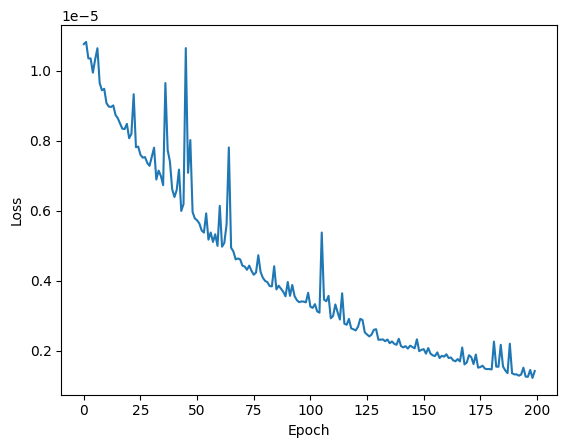

In [63]:
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [70]:
model.eval()
with torch.no_grad():
    corrects = 0
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        y_hat = model(x)
        pred = (y_hat > 0.5).to(torch.int32)
        pred = torch.squeeze(pred)
        corrects += (pred == y).sum().item()
    accuracy = corrects / len(test_loader.dataset) * 100

print(f'Accuracy: {accuracy:.3f}')

Accuracy: 99.123
